# 05 - SVM trên Digits

Mục tiêu: nhận dạng chữ số viết tay từ ảnh 8x8 bằng SVM với cấu hình `C=100`, `gamma=0.001`, đồng thời đánh giá bằng confusion matrix và classification report.

## 1. Load data và EDA ngắn

Shape X: (1797, 64)
Ảnh gốc: (1797, 8, 8) | Missing values: 0
Phân bố target:
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64


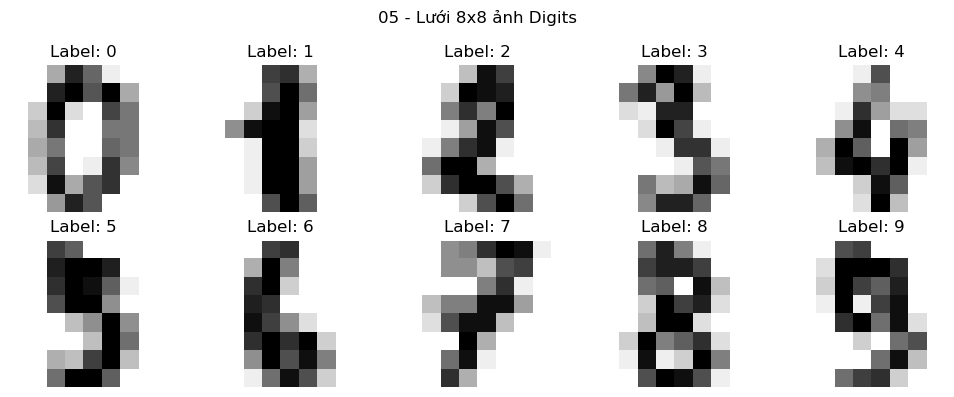

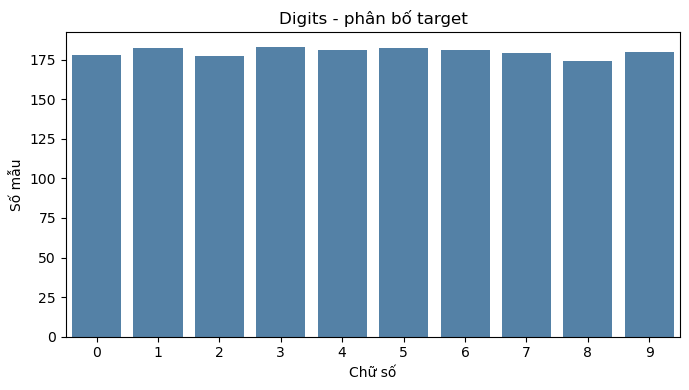

In [1]:
import csv
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_digits
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = 101
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FIGURES = ROOT / 'figures'
FIGURES.mkdir(exist_ok=True)

digits = load_digits()
X, y = digits.data, digits.target
print('Shape X:', X.shape)
print('Ảnh gốc:', digits.images.shape, '| Missing values:', int(np.isnan(X).sum()))
print('Phân bố target:')
print(pd.Series(y).value_counts().sort_index())

def view_digit(index):
    plt.imshow(digits.images[index], cmap='gray_r', interpolation='nearest')
    plt.title(f'Digit: {y[index]}')
    plt.axis('off')

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, index in zip(axes.ravel(), range(10)):
    ax.imshow(digits.images[index], cmap='gray_r', interpolation='nearest')
    ax.set_title(f'Label: {y[index]}')
    ax.axis('off')
plt.suptitle('05 - Lưới 8x8 ảnh Digits')
plt.tight_layout()
plt.savefig(FIGURES / '05_digits_samples.png', dpi=150)
plt.show()

plt.figure(figsize=(7, 4))
sns.countplot(x=y, color='steelblue')
plt.title('Digits - phân bố target')
plt.xlabel('Chữ số')
plt.ylabel('Số mẫu')
plt.tight_layout()
plt.savefig(FIGURES / '05_digits_target_distribution.png', dpi=150)
plt.show()

## 2. Tiền xử lý và chia dữ liệu theo thứ tự mẫu

In [2]:
# Theo thứ tự mẫu: 1500 mẫu đầu để train, phần còn lại làm test (dùng [1500:], không phải [1501:]).
X_train, y_train = X[:1500], y[:1500]
X_test, y_test = X[1500:], y[1500:]
print('Train:', X_train.shape, '| Test:', X_test.shape)

# Scale trong Pipeline để SVM hoạt động ổn định và không leakage từ test.
model = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(C=100, gamma=0.001, kernel='rbf'))
])

Train: (1500, 64) | Test: (297, 64)


## 3. Train

In [3]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print('Đã train SVC với C=100, gamma=0.001, kernel=rbf')

Đã train SVC với C=100, gamma=0.001, kernel=rbf


## 4. đánh giá

accuracy     0.9158
precision    0.9232
recall       0.9158
f1           0.9152
dtype: float64
              precision    recall  f1-score   support

           0     1.0000    0.9630    0.9811        27
           1     0.8611    1.0000    0.9254        31
           2     1.0000    1.0000    1.0000        27
           3     0.9091    0.6667    0.7692        30
           4     1.0000    0.9091    0.9524        33
           5     0.9062    0.9667    0.9355        30
           6     0.9667    0.9667    0.9667        30
           7     0.9062    0.9667    0.9355        30
           8     0.7143    0.8929    0.7937        28
           9     0.9630    0.8387    0.8966        31

    accuracy                         0.9158       297
   macro avg     0.9227    0.9170    0.9156       297
weighted avg     0.9232    0.9158    0.9152       297



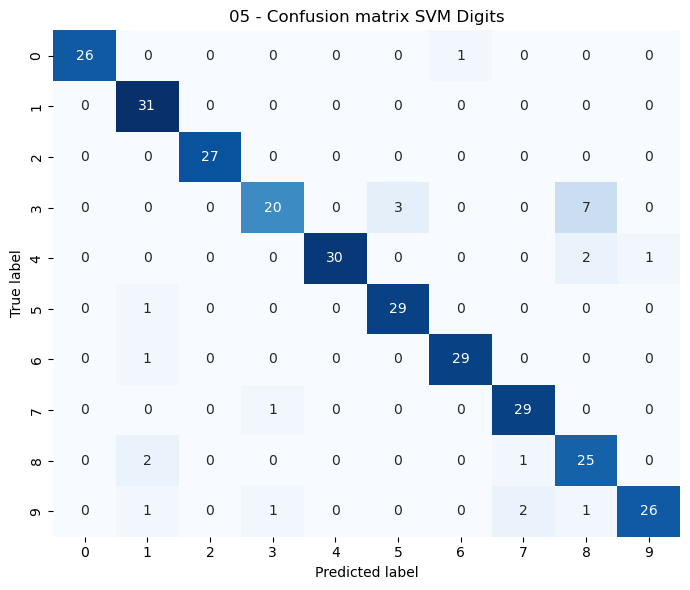

In [4]:
metrics = {
    'accuracy': accuracy_score(y_test, y_pred),
    'precision': precision_score(y_test, y_pred, average='weighted', zero_division=0),
    'recall': recall_score(y_test, y_pred, average='weighted', zero_division=0),
    'f1': f1_score(y_test, y_pred, average='weighted', zero_division=0),
}
print(pd.Series(metrics).round(4))
print(classification_report(y_test, y_pred, digits=4, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('05 - Confusion matrix SVM Digits')
plt.tight_layout()
plt.savefig(FIGURES / '05_digits_svm_confusion_matrix.png', dpi=150)
plt.show()

## 5. Nhận xét và bảng kết quả tóm tắt

Digits có nhiều lớp nhưng các đặc trưng pixel cho phép SVM RBF phân tách tốt. Cấu hình `C` và `gamma` được giữ đúng theo đề mẫu; StandardScaler được đặt trong Pipeline để tránh leakage. Sai số tập trung ở các chữ số có nét viết tương tự nhau, thể hiện trên confusion matrix.

In [5]:
summary_path = FIGURES / 'results_summary.csv'
rows = []
if summary_path.exists():
    with summary_path.open(newline='', encoding='utf-8') as f:
        rows = [r for r in csv.DictReader(f) if r['notebook'] != '05_digits_svm']
fieldnames = ['notebook', 'dataset', 'model', 'best_params', 'accuracy', 'precision', 'recall', 'f1', 'roc_auc']
rows.append({
    'notebook': '05_digits_svm', 'dataset': 'digits', 'model': 'SVM',
    'best_params': repr({'C': 100, 'gamma': 0.001, 'kernel': 'rbf'}),
    'accuracy': metrics['accuracy'], 'precision': metrics['precision'],
    'recall': metrics['recall'], 'f1': metrics['f1'], 'roc_auc': ''
})
with summary_path.open('w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(rows)
print('Đã cập nhật:', summary_path)

Đã cập nhật: D:\ML_Lab_Group_2026\Lab05_ModelTraining\Lab05\figures\results_summary.csv
